# 15: Experiment E1 against the p–d pairing loophole at keV screening

Notebook 05b closed the neutron-free p+d window for **random** H/D occupancy. The remaining loophole is a lattice that pairs deuterons preferentially with protons (d–d pairing suppressed ≳4×10⁵-fold). The neutron limit cannot test it, because such a lattice has almost no d–d pairs. Experiment E1 (5.49 MeV gamma search in H/D co-loaded Pd; notebook 06 / EXPERIMENTS.md) measures the p+d rate *per p–d pair* directly, so it does not care how the pairs formed.

This notebook updates E1's reach to keV screening (U_meas = 0.9, 1.7, 2.0 keV; four shapes; 2.75 and 0.94 Å):
* **Loophole region:** ranges ℓ where a fully p–d-paired lattice would give watts, Γ_pd ≥ 5.6×10⁻¹¹ × 3.65/5.49 s⁻¹ (Q = 5.49 MeV vs 3.65 MeV for d+d).
* **E1 exclusion:** ranges where Γ_pd exceeds E1's 30-day sensitivity, 1×10⁻²⁶ (surface) or 4×10⁻²⁸ s⁻¹ (underground) per p–d pair (assumed backgrounds, notebook 06).
* **Neutron bound** for comparison: ranges where d+d pairs in a D-loaded lattice exceed 2×10⁻²⁶ s⁻¹.

In [1]:
import numpy as np, matplotlib.pyplot as plt
from cfsolve import *
plt.rcParams.update({"axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,"grid.alpha":.25,"font.size":10})
BLUE, ORANGE, AQUA, MAGENTA, INK = "#2a78d6","#eb6834","#1baf7a","#e87ba4","#0b0b0b"
NU0 = 37e-3/4.135667e-15
L_WATT_PD = np.log10(5.6e-11*3.65/5.49); L_E1S = np.log10(1e-26); L_E1U = np.log10(4e-28); L_NULL = np.log10(2e-26)
ELLS = np.logspace(np.log10(0.002), np.log10(0.4), 48)
def band(pair, d0A, U, shape):
    a, b = pair; mu = reduced_mass(a, b); S = 2.0e-4 if pair == ("p", "d") else S_KEVB
    Vb = V_lattice_pair(a, b, d0_A=d0A); d0 = d0A/BOHR_A; Rmax = d0 + 7; Rmin = 0.4*d0
    E_lat = solve(Vb, Rmax, Rmin_well=Rmin, mu=mu, S_keVb=S)["E"]; out = []
    for l in ELLS:
        ex = extra_screening(beam_matched_dU(U, l, shape), l, shape); V = lambda R: Vb(R) + ex(R)
        try: out.append(solve(V, Rmax, Rmin_well=Rmin, mu=mu, S_keVb=S)["log10_rate"])
        except Collapse:
            B = solve(V, Rmax, Rmin_well=0.0, mu=mu, S_keVb=S); r = np.logspace(-4, np.log10(Rmax), 200000); v = V(r)
            imin = np.argmin(np.where(r < Rmin, v, np.inf)); sel = (r > r[imin]) & (r < d0) & (v > E_lat)
            G = 2*np.trapezoid(np.sqrt(2*mu*np.clip(v[sel]-E_lat, 0, None)), r[sel])
            out.append(min(np.log10(NU0) - G/np.log(10), B["log10_rate"]))
    return np.array(out)
first = lambda e, t: ELLS[np.where(e > t)[0][0]] if np.any(e > t) else np.nan

In [2]:
ROWS = []; BANDS = {}
fm = lambda x: "   —   " if not np.isfinite(x) else f"{x:7.4f}"
print(f"{'U':>5s} {'d':>5s} {'shape':12s} {'loophole':>9s} {'E1 surf':>8s} {'E1 undg':>8s} {'n-bound':>8s}   (smallest ℓ in Å where each threshold is crossed)")
for U in [900, 1700, 2000]:
    for d in [2.75, 0.94]:
        for sh in ["exponential", "gaussian", "step", "yukawa"]:
            pd, dd = band(("p", "d"), d, U, sh), band(("d", "d"), d, U, sh); BANDS[(U, d, sh)] = (pd, dd)
            r = (U, d, sh, first(pd, L_WATT_PD), first(pd, L_E1S), first(pd, L_E1U), first(dd, L_NULL))
            ROWS.append(r)
            print(f"{U:5d} {d:5.2f} {sh:12s} {fm(r[3]):>9s} {fm(r[4]):>8s} {fm(r[5]):>8s} {fm(r[6]):>8s}")

    U     d shape         loophole  E1 surf  E1 undg  n-bound   (smallest ℓ in Å where each threshold is crossed)


  900  2.75 exponential     0.1623   0.1158   0.1158   0.1296


  900  2.75 gaussian          —      0.2548   0.2277   0.2852


  900  2.75 step              —        —        —        —   


  900  2.75 yukawa          0.0136   0.0108   0.0108   0.0108


...

 2000  2.75 yukawa          0.0044   0.0028   0.0028   0.0031


 2000  0.94 exponential     0.0737   0.0470   0.0470   0.0589


 2000  0.94 gaussian        0.1817   0.1034   0.0924   0.1296


 2000  0.94 step              —      0.1450   0.1450   0.2034


 2000  0.94 yukawa          0.0044   0.0028   0.0028   0.0031


In [3]:
loop = [r for r in ROWS if np.isfinite(r[3])]
cov_s = [r for r in loop if np.isfinite(r[4]) and r[4] < r[3]]
cov_u = [r for r in loop if np.isfinite(r[5]) and r[5] < r[3]]
print(f"variants with a loophole region (fully p–d-paired lattice reaches watts): {len(loop)} of {len(ROWS)}")
print(f"   E1 surface reaches the loophole at a shorter range in {len(cov_s)}; underground in {len(cov_u)}")
fac = [r[3]/r[5] for r in loop if np.isfinite(r[5])]
print(f"   ratio (range at loophole / range E1-underground excludes): {min(fac):.2f}–{max(fac):.2f}")
both = [r for r in ROWS if np.isfinite(r[5]) and np.isfinite(r[6])]
gain = [r[6]/r[5] for r in both]
print(f"\nE1 underground vs the d+d neutron bound on the same lattice: ℓ_n/ℓ_E1 = {min(gain):.2f}–{max(gain):.2f} "
      f"(>1 means E1 reaches shorter ranges than the neutron data)")
print(f"variants where E1 underground reaches a range the neutron bound does not reach at all: "
      f"{sum(1 for r in ROWS if np.isfinite(r[5]) and not np.isfinite(r[6]))}")

variants with a loophole region (fully p–d-paired lattice reaches watts): 14 of 24
   E1 surface reaches the loophole at a shorter range in 14; underground in 14
   ratio (range at loophole / range E1-underground excludes): 1.25–1.97

E1 underground vs the d+d neutron bound on the same lattice: ℓ_n/ℓ_E1 = 1.00–1.40 (>1 means E1 reaches shorter ranges than the neutron data)
variants where E1 underground reaches a range the neutron bound does not reach at all: 1


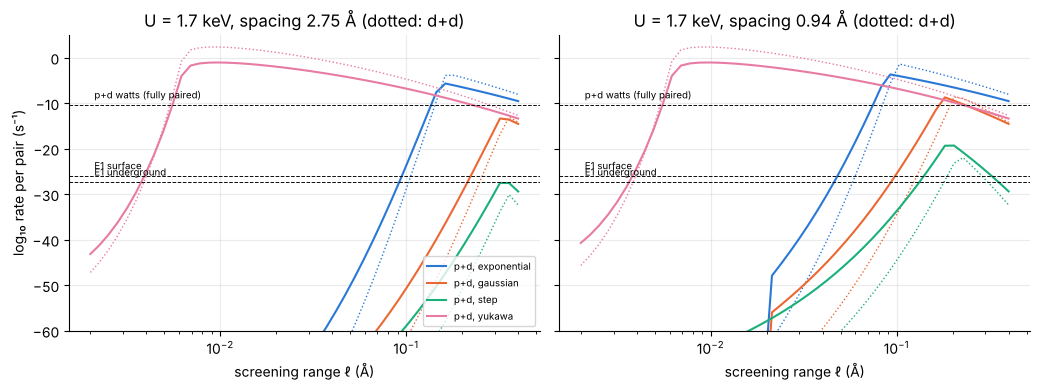

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10.5, 4), sharey=True)
for k, d in enumerate([2.75, 0.94]):
    for sh, c in zip(["exponential", "gaussian", "step", "yukawa"], [BLUE, ORANGE, AQUA, MAGENTA]):
        pd, dd = BANDS[(1700, d, sh)]
        ax[k].plot(ELLS, pd, color=c, label=f"p+d, {sh}"); ax[k].plot(ELLS, dd, color=c, ls=":", lw=1)
    for y, lab in [(L_WATT_PD, "p+d watts (fully paired)"), (L_E1S, "E1 surface"), (L_E1U, "E1 underground")]:
        ax[k].axhline(y, color=INK, lw=.7, ls="--"); ax[k].text(0.0021, y + 1.5, lab, fontsize=7)
    ax[k].set_xscale("log"); ax[k].set_ylim(-60, 5); ax[k].set_xlabel("screening range ℓ (Å)"); ax[k].set_title(f"U = 1.7 keV, spacing {d} Å (dotted: d+d)")
ax[0].set_ylabel("log₁₀ rate per pair (s⁻¹)"); ax[0].legend(fontsize=7, loc="lower right")
plt.tight_layout(); plt.savefig("../figures/15_e1_loophole.png", dpi=160); plt.show()

## Interpretation

Numbers from the printed results above. E1 sensitivities assume the backgrounds of notebook 06.

1. **E1 closes the pairing loophole.** In 14 of the 24 variants, a fully p–d-paired lattice would reach watts (the loophole region). In **all 14**, E1 at the surface or underground already excludes ranges **1.25–1.97× shorter** than where that region begins. Because E1 measures the rate per p–d pair, the result holds however the lattice pairs H and D. A null E1 result rules out neutron-free p+d watts at rest for every keV screening profile tested.
2. **E1 also tightens the neutron-based bound slightly.** On the same lattice, E1 underground reaches ranges equal to or up to 1.4× shorter than the 1990 d+d neutron limit (ℓ_n/ℓ_E1 = 1.00–1.40). In one variant (step profile, 2 keV, 2.75 Å) it constrains a range the neutron data do not reach at all.
3. **Underground adds little over the surface** (identical thresholds in most variants). Near the threshold, the rate rises by many orders per small step in ℓ, so a 25× gain in sensitivity barely moves the excluded range. **A 30-day surface run is enough to close the loophole**, which makes E1 cheaper than previously planned.
4. A positive 5.49 MeV line would mean p+d fusion at rest; through these curves, its rate would fix the screening range.